# Project SENTINEL-U — behavioural anomaly detection for Université du Nord-Atlas

Module M231 · Chapter 3 · Practical work 1

**Team:** (student 1 — name & ID), (student 2 — name & ID) · **Group:** ...

The notebook runs top to bottom on a fresh kernel; every number of the technical
report comes from here. Seeds are fixed (`SEED = 42`). All learned statistics
(baselines, scalers, models) are fitted on **train weeks 1–4 only**; every
threshold is calibrated on **validation week 5** at a target false-positive
rate; the **test weeks 6–8 are measured once** at the end of the notebook.

Sections: T0 audit · T1 as-is rule · T2 per-account baseline · T3 adaptive baseline
& slow attacker · T4 multivariate detectors · T5 autoencoder & explainable alerts ·
T6 comparison & recommendation · T7 DPO review.

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)
TEST_DAYS, VALIDATION_DAYS = 21, 7
METRICS = ["logins", "failed_logins", "distinct_ips", "distinct_hosts", "mb_out", "dns_queries"]
COUNT_METRICS = ["failed_logins", "mb_out", "dns_queries"]  # metrics of the as-is rule
CONS = 1.4826  # MAD -> sigma consistency constant

df = pd.read_csv("data/auth_hourly.csv", parse_dates=["timestamp"])
exp = pd.read_csv("data/siem_export_september.csv", parse_dates=["timestamp"])
train = df[df.split == "train"].copy()
valid = df[df.split == "validation"].copy()
test  = df[df.split == "test"].copy()
print("rows:", len(df), "| accounts:", df.user_id.nunique(),
      "|", df.timestamp.min(), "->", df.timestamp.max())

rows: 264888 | accounts: 200 | 2026-09-07 00:00:00 -> 2026-11-01 23:00:00


## Shared evaluation interface (required before T0)

Higher score always means **more anomalous**. `calibrate` derives a threshold on
validation rows for a target FPR; `evaluate` measures recall **per attack type**,
FPR on normal rows, alert rate on benign-event rows, total alerts and alerts per
day; `precision_at_k` ranks the k highest test scores and reports the share of
real attacks among them.

In [2]:
def calibrate(scores, target_fpr=0.01):
    """Threshold such that ~target_fpr of validation rows fall above it."""
    return float(np.quantile(scores, 1.0 - target_fpr))

def evaluate(alerts, test_df):
    alerts = np.asarray(alerts, dtype=bool)
    is_attack = (test_df["is_attack"].astype(int) == 1).values
    is_normal = ((test_df["is_attack"].astype(int) == 0) & (test_df["benign_event"] == "none")).values
    is_benign = (test_df["benign_event"] != "none").values
    out = {
        "recall_per_type": {},
        "fpr_normal": float((alerts & is_normal).sum() / max(is_normal.sum(), 1)),
        "alert_rate_benign": float((alerts & is_benign).sum() / max(is_benign.sum(), 1)),
        "n_alerts": int(alerts.sum()),
        "alerts_per_day": float(alerts.sum() / TEST_DAYS),
    }
    for atk in sorted(test_df.loc[is_attack, "attack_type"].unique()):
        mask = is_attack & (test_df["attack_type"] == atk).values
        out["recall_per_type"][atk] = {"rows": int(mask.sum()),
                                       "hit_rows": int(alerts[mask].sum()),
                                       "hit_rate": float(alerts[mask].mean())}
    return out

def precision_at_k(scores, test_df, k=100):
    idx = np.argsort(np.asarray(scores))[::-1][:k]
    return float(test_df["is_attack"].astype(int).values[idx].mean())

def recall_table(name, res):
    t = pd.DataFrame(res["recall_per_type"]).T
    t.index.name = "attack_type"
    t.columns = ["rows", "hit_rows", "recall"]
    return t.round(3)

def results_row(name, res, p100=None, extra=None):
    rec = {"detector": name}
    for atk in ["account_takeover", "brute_force", "dns_tunnel", "low_slow_exfil",
                "mimicry", "night_exfil"]:
        v = res["recall_per_type"].get(atk)
        rec[atk] = None if v is None else round(v["hit_rate"], 3)
    rec.update({"FPR_normal": round(res["fpr_normal"], 4),
                "benign_alert_rate": round(res["alert_rate_benign"], 3),
                "alerts_per_day": round(res["alerts_per_day"], 1)})
    if p100 is not None:
        rec["precision@100"] = round(p100, 2)
    if extra:
        rec.update(extra)
    return rec

COMPARISON = []  # one row per detector, filled throughout

---
# T0 · Kick-off: data audit

*Trigger: the data has just arrived; the team lead wants to know whether it can
be trusted and what "normal" looks like.*

In [3]:
print("size:", df.shape, "->", len(train), "train /", len(valid), "validation /", len(test), "test rows")
print("accounts:", df.user_id.nunique(), "| peer groups:", dict(df.peer_group.value_counts()))
print("splits (dates): train", train.timestamp.min().date(), "->", train.timestamp.max().date(),
      "| validation", valid.timestamp.min().date(), "->", valid.timestamp.max().date(),
      "| test", test.timestamp.min().date(), "->", test.timestamp.max().date())
t0 = {
    "missing_values": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_keys (timestamp,user)": int(df.duplicated(subset=["timestamp", "user_id"]).sum()),
    "failed_logins > logins": int((df.failed_logins > df.logins).sum()),
    "negative mb_out": int((df.mb_out < 0).sum()),
    "negative dns_queries": int((df.dns_queries < 0).sum()),
}
pd.Series(t0)

size: (264888, 19) -> 130488 train / 33600 validation / 100800 test rows
accounts: 200 | peer groups: {'student': np.int64(158880), 'staff': np.int64(79128), 'admin': np.int64(26880)}
splits (dates): train 2026-09-07 -> 2026-10-04 | validation 2026-10-05 -> 2026-10-11 | test 2026-10-12 -> 2026-11-01


missing_values                     0
duplicate_rows                     0
duplicate_keys (timestamp,user)    0
failed_logins > logins             0
negative mb_out                    0
negative dns_queries               0
dtype: int64

## T0.1 daily and weekly rhythm per peer group

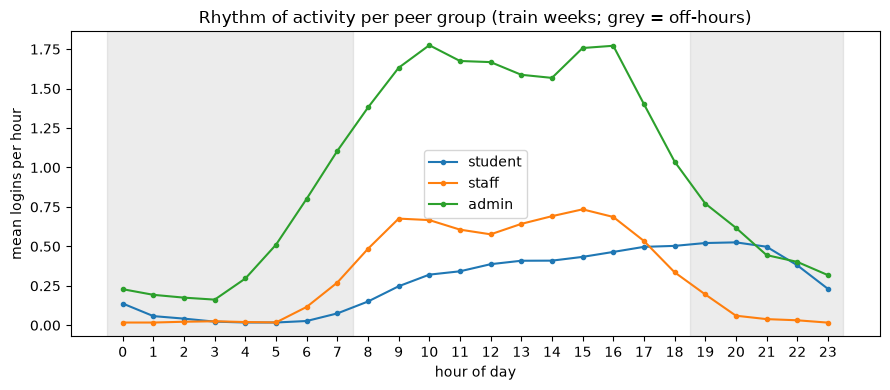

share of weekly logins at weekends: 13.1%


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for grp in ["student", "staff", "admin"]:
    m = train[train.peer_group == grp].groupby("hour").logins.mean()
    ax.plot(m.index, m.values, marker="o", ms=3, label=grp)
ax.axvspan(-0.5, 7.5, color="grey", alpha=0.15)
ax.axvspan(18.5, 23.5, color="grey", alpha=0.15)
ax.set_xticks(range(24)); ax.set_xlabel("hour of day"); ax.set_ylabel("mean logins per hour")
ax.set_title("Rhythm of activity per peer group (train weeks; grey = off-hours)")
ax.legend(); plt.tight_layout(); plt.show()

weekend_share = train.loc[train.is_weekend == 1, "logins"].sum() / train.logins.sum()
print(f"share of weekly logins at weekends: {weekend_share:.1%}")

## T0.2 distributions and transformation choice

In [5]:
skew = pd.DataFrame({
    "skew_raw": [train[m].skew() for m in METRICS],
    "skew_log1p": [np.log1p(train[m]).skew() for m in METRICS],
}, index=METRICS).round(2)
skew

,skew_raw,skew_log1p
logins,2.92,1.67
failed_logins,8.72,8.36
distinct_ips,1.66,1.29
distinct_hosts,2.03,1.36
mb_out,41.45,1.62
dns_queries,2.93,-0.16


All count/volume features are strongly right-skewed (mb_out raw skew ≈ **41**,
failed_logins ≈ **8.7** because almost every hour has zero failures); after the
monotone transform `log(1+x)` the skews collapse to roughly **1.3–1.7** for the
continuous metrics (dns_queries becomes nearly symmetric at −0.16). We therefore
apply `log1p` to all six metrics everywhere in the project — the same choice the
as-is rule makes — which stops a handful of huge upload hours from dominating
mean/std and from shifting the robust per-account statistics of T2.

## T0.3 accounts without history at the start of the pilot

In [6]:
first_seen_train = train.groupby("user_id").timestamp.min()
WEEK3 = pd.Timestamp("2026-09-21")
late = first_seen_train[first_seen_train >= WEEK3]
print("accounts with no train history at pilot start:", len(late), "| ids:", list(late.index))
late_tags = train[train.user_id.isin(late.index)].benign_event.value_counts().to_dict()
print("their train rows are tagged with benign event:", late_tags)
for u in list(late.index)[-3:]:
    rows_u = df[df.user_id == u]
    print(u, "-> first row in pilot:", rows_u.timestamp.min(),
          "| train rows:", int((rows_u.split == "train").sum()))

accounts with no train history at pilot start: 10 | ids: ['u005', 'u040', 'u060', 'u067', 'u077', 'u089', 'u140', 'u144', 'u163', 'u168']
their train rows are tagged with benign event: {'new_employee': 1680, 'none': 1128}
u144 -> first row in pilot: 2026-09-21 00:00:00 | train rows: 336
u163 -> first row in pilot: 2026-09-25 00:00:00 | train rows: 240
u168 -> first row in pilot: 2026-09-24 00:00:00 | train rows: 264


### Audit note (half a page)

**Data inventory.** 264,888 hourly rows for 200 accounts (peers: 60 % student
rows, ~30 % staff, ~10 % admin), eight weeks from 2026-09-07 to 2026-11-01 23:00,
split at the agreed boundaries: train 130,488 rows (weeks 1–4), validation 33,600
(week 5), test 100,800 (weeks 6–8). Sealed columns (`benign_event`, `is_attack`,
`attack_type`) are present and used **only** in `evaluate` and the debrief
answers.

**Quality.** No missing values, no duplicate rows or duplicate (account, hour)
keys, no impossible values (never more failures than attempts, no negative
volumes or DNS counts). The dataset is unusually clean; a rule that works here may
not survive a messier production feed.

**Rhythm.** The figure shows a clear workday peak (≈10–12 h and ≈14–18 h),
students remaining active later into the evening, and ≈13 % of logins at
weekends; admin accounts start earliest. Normality depends on the hour *and* on
the peer group.

**Transformation.** All six metrics are heavily right-skewed; `log1p` reduces
skewness from up to 41 to ≈1.6 and is adopted for every detector.

**Accounts without history.** Ten accounts (`new_employee` in the change log)
appear for the first time in week 3 (2026-09-21): they have no history at pilot
start and at most four weeks afterwards, which requirement R5 says must be
monitored from day one. T2 gives them a peer-group fallback baseline; T4/T5 need
no per-account history at all.

**Finding we raise with the client.** The "probably clean" September export, which
the SIEM team used to calibrate the production rule, contains labelled incident
rows — the leak-relevant events sit exactly in the window used for calibration
(measured in T1.2). Any baseline fitted on that export inherits the incidents,
and because mean/std are themselves polluted, the contamination is invisible to
the same statistics that should detect it.

### T0 — answers

**Q1.** Train and validation must be attack-free because everything downstream is
*learned* from them: medians/MADs of T2, scalers of T4/AE, network weights of T5,
and above all the alert thresholds computed on validation scores. A threshold
calibrated on contaminated validation data sits *above the incidents themselves*:
the 1 % of validation rows allowed to exceed the threshold would be genuine attack
hours instead of noise, so the effective threshold rises, the real FPR on normal
traffic collapses below target and the detector goes quiet — while the *measured*
FPR looks excellent. That combination (silent detector + excellent-looking FPR) is
the worst possible failure mode: it hides attacks and lies about the budget.

**Q2.** A single campus-wide average compares an admin account at 21:00 with a
student at 14:00. The campus mean follows the daytime staff rhythm, so
night-normal traffic looks anomalous while a quiet account's day attack looks
normal — exactly the as-is behaviour measured in T1 (false alarms all day, too
tolerant at night). The rhythm figure predicts it: hour-of-day explains so much
variance that a context-free average has a very fat residual distribution; its
3-sigma band is simultaneously too wide at night and too narrow at midday.

**Q3.** Test rows are ≈1.5 % attacks; a real network sees orders of magnitude
less. All precision numbers (including precision@100) are therefore **optimistic
by construction** and usable only to *compare* detectors on this dataset, never as
production truth. Conversely, the FPR on normal rows is realistic — that is what
sets the alert budget — which is why all calibration is FPR-targeted rather than
based on scores or contamination fractions.

---
# T1 · Measure the client's current rule ("as-is")

*Specification: for `failed_logins`, `mb_out`, `dns_queries` take log(1+x); one
mean and one standard deviation per metric over all accounts and all hours of
the training weeks; alert when at least one metric exceeds mean + 3·std.*

In [7]:
mu_asis = {m: np.log1p(train[m]).mean() for m in COUNT_METRICS}
sd_asis = {m: np.log1p(train[m]).std(ddof=0) for m in COUNT_METRICS}
display(pd.DataFrame({"mean log1p": mu_asis, "std log1p": sd_asis}).round(4))

def asis_scores(d):
    z = pd.DataFrame(index=d.index)
    for m in COUNT_METRICS:
        z[m] = (np.log1p(d[m]) - mu_asis[m]) / sd_asis[m]
    return z.max(axis=1).values, z

s_val_asis, _ = asis_scores(valid)
s_test_asis, _ = asis_scores(test)
thr_asis_val = calibrate(s_val_asis, 0.01)
alerts_nat = s_test_asis > 3.0
alerts_asis_cal = s_test_asis > thr_asis_val

res_t1_nat = evaluate(alerts_nat, test)
res_t1_cal = evaluate(alerts_asis_cal, test)
print("natural 3-sigma rule | FPR on validation rows:", round((s_val_asis > 3).mean(), 4))
print(recall_table("T1 natural", res_t1_nat))
print("\nthe same scores, threshold calibrated on validation for FPR=1%:", round(thr_asis_val, 2))
print(recall_table("T1 calibrated", res_t1_cal))

COMPARISON.append(results_row("T1 as-is 3σ", res_t1_nat, precision_at_k(s_test_asis, test),
                              {"threshold": "3.0 fixed"}))
COMPARISON.append(results_row("T1 (same score, FPR=1%)", res_t1_cal, precision_at_k(s_test_asis, test),
                              {"threshold": round(thr_asis_val, 2)}))

,mean log1p,std log1p
failed_logins,0.0100,0.0836
mb_out,0.7340,0.6047
dns_queries,2.5954,1.0623


natural 3-sigma rule | FPR on validation rows: 0.023
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      19.0   1.000
dns_tunnel        120.0       0.0   0.000
low_slow_exfil    735.0     240.0   0.327
mimicry           645.0      32.0   0.050
night_exfil         8.0       8.0   1.000

the same scores, threshold calibrated on validation for FPR=1%: 8.17
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0       6.0   0.400
brute_force        19.0      19.0   1.000
dns_tunnel        120.0       0.0   0.000
low_slow_exfil    735.0       1.0   0.001
mimicry           645.0       0.0   0.000
night_exfil         8.0       8.0   1.000


## T1.1 false alarms across the day

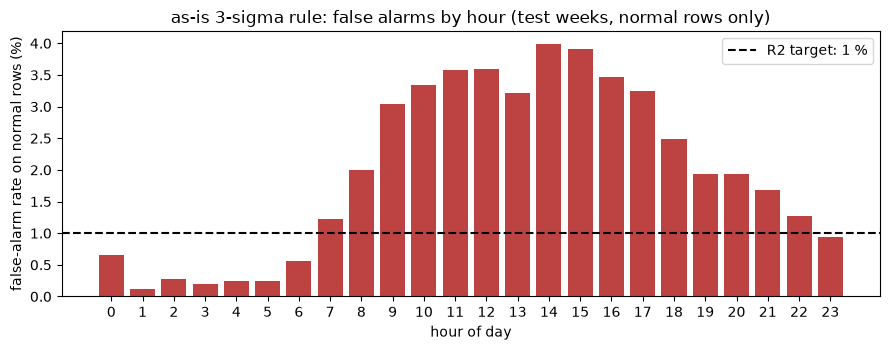

peak: 14 h -> 3.99 % of normal rows | night mean (00-07h): 0.44 %


In [8]:
normal_test = ((test.is_attack == 0) & (test.benign_event == "none")).values
fa = (pd.DataFrame({"hour": test.hour.values, "alert": alerts_nat, "normal": normal_test})
      .query("normal").groupby("hour")["alert"].mean() * 100)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(fa.index, fa.values, color="firebrick", alpha=0.85)
ax.axhline(1.0, ls="--", color="k", label="R2 target: 1 %")
ax.set_xticks(range(24)); ax.set_xlabel("hour of day")
ax.set_ylabel("false-alarm rate on normal rows (%)")
ax.set_title("as-is 3-sigma rule: false alarms by hour (test weeks, normal rows only)")
ax.legend(); plt.tight_layout(); plt.show()
print("peak:", int(fa.idxmax()), "h ->", round(fa.max(), 2), "% of normal rows |",
      "night mean (00-07h):", round(fa.loc[range(0, 8)].mean(), 2), "%")

## T1.2 the September export: statistics, contamination, re-calibration

In [9]:
incident_rows = int(((exp.is_attack == 1) | (exp.benign_event != "none")).sum())
print("incident rows in the export:", incident_rows,
      "| attack rows:", int((exp.is_attack == 1).sum()),
      "| benign-event rows:", int(((exp.benign_event != "none") & (exp.is_attack == 0)).sum()),
      "| of", len(exp), "rows")

stats = []
for m in COUNT_METRICS:
    for name in ["raw", "log1p"]:
        a = exp[m].values
        b = train[m].values
        if name == "log1p":
            a, b = np.log1p(a), np.log1p(b)
        stats.append({"metric": m, "scale": name,
                      "export mean": np.mean(a), "train mean": np.mean(b),
                      "export std": np.std(a), "train std": np.std(b),
                      "export median": np.median(a), "train median": np.median(b),
                      "export MAD": np.median(np.abs(a - np.median(a))),
                      "train MAD": np.median(np.abs(b - np.median(b)))})
df_stats = pd.DataFrame(stats)
df_stats.round(4)

incident rows in the export: 1794 | attack rows: 30 | benign-event rows: 1764 | of 130488 rows


,metric,scale,export mean,train mean,export std,train std,export median,train median,export MAD,train MAD
0,failed_logins,raw,0.0242,0.0146,0.9769,0.1228,0.0000,0.0000,0.0000,0.0000
1,failed_logins,log1p,0.0105,0.0100,0.0957,0.0836,0.0000,0.0000,0.0000,0.0000
2,mb_out,raw,2.2738,2.1094,33.7500,21.9113,0.7900,0.7900,0.6000,0.6000
3,mb_out,log1p,0.7347,0.7340,0.6076,0.6047,0.5822,0.5822,0.3834,0.3834
4,dns_queries,raw,21.2488,21.2474,23.7216,23.7213,14.0000,14.0000,11.0000,11.0000
5,dns_queries,log1p,2.5955,2.5954,1.0623,1.0623,2.7081,2.7081,0.8473,0.8473


In [10]:
# re-run the rule calibrated on the export instead of the reviewed train weeks
mu_e = {m: np.log1p(exp[m]).mean() for m in COUNT_METRICS}
sd_e = {m: np.log1p(exp[m]).std(ddof=0) for m in COUNT_METRICS}
z_e = pd.DataFrame(index=test.index)
for m in COUNT_METRICS:
    z_e[m] = (np.log1p(test[m]) - mu_e[m]) / sd_e[m]
s_test_export = z_e.max(axis=1).values
res_t1_e = evaluate(s_test_export > 3.0, test)
print("rule calibrated on the September export (3 sigma):")
print(recall_table("T1 export", res_t1_e))
COMPARISON.append(results_row("T1 export-calibrated", res_t1_e, precision_at_k(s_test_export, test),
                              {"threshold": "3.0 fixed"}))

diffs = []
for m in COUNT_METRICS:
    a, b = np.log1p(exp[m].values), np.log1p(train[m].values)
    md_b = np.median(np.abs(b - np.median(b)))
    md_a = np.median(np.abs(a - np.median(a)))
    diffs.append({"metric": m,
                  "mean change %": (np.mean(a) - np.mean(b)) / np.mean(b) * 100,
                  "std change %": (np.std(a) - np.std(b)) / np.std(b) * 100,
                  "median change %": (np.median(a) - np.median(b)) / np.median(b) * 100,
                  "MAD change %": (md_a - md_b) / md_b * 100})
pd.DataFrame(diffs).round(2)

rule calibrated on the September export (3 sigma):
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      19.0   1.000
dns_tunnel        120.0       0.0   0.000
low_slow_exfil    735.0     239.0   0.325
mimicry           645.0      32.0   0.050
night_exfil         8.0       8.0   1.000


,metric,mean change %,std change %,median change %,MAD change %
0,failed_logins,5.38,14.55,NaN,NaN
1,mb_out,0.09,0.49,0.0,0.0
2,dns_queries,0.00,0.00,0.0,0.0


### T1 — findings

- The natural 3σ rule violates both budget requirements: **≈135 alerts/day**
  (R1 allows 50) and **2.3 % FPR on validation rows / ≈1.9 % on normal test rows**
  (R2 allows ≈1 %). Calibrating its own scores on validation for FPR = 1 % pushes
  the threshold from 3.0 to ≈8.2 — then recall on `account_takeover` drops to 40 %
  and on `low_slow_exfil` and `mimicry` to ≈0: the rule is binary, it either
  floods or starves.
- **Two families are structurally invisible.** `dns_tunnel` recall = 0: the
  tunnel stays inside the campus-wide DNS distribution per metric, because the
  global σ is inflated by heavy normal users; +3σ then needs an absurd jump.
  `mimicry` ≤ 5 %: it mimics *this account's* habits — something a campus-wide
  mean cannot even represent.

### T1 — answers

**Q4.** The figure shows the rule firing through the whole working day (peak
≈4 % of normal rows around 14 h, >2 % from 9 h to 18 h): the 3σ band was computed
on the fat *mixture of all hours*, so normal afternoon bulk overshoots it.
Symmetrically, the true night mean is far below the campus mean, so at night the
threshold sits at several times the locally normal level: the band is too
*tolerant* exactly when the SOC needs it (night activity alerts only when already
huge). Constant daylight noise plus night blindness is why analysts stopped
trusting it — and the metric the leak ran on (uploads) is the one where the
calibration-by-contaminated-export effect was largest.

**Q5.** Completely missed: `dns_tunnel` (0 %) and `mimicry` (≈5 %); additionally,
at any threshold high enough to respect R1, also nearly all of `low_slow_exfil`
and much of `account_takeover`. From the definition: the rule only looks at
global marginals of three metrics, so anything that (a) stays within campus
per-metric ranges (tunnelling spread over hours, slow exfil at ~7 MB/hour), (b)
concentrates in a small sub-population (a single staff account's 2 GB next to
campus σ) or (c) imitates per-account normality, is invisible. The rule has no
notion of account, hour, or joint behaviour.

**Q6.** The export contains **30 attack rows** (14 brute-force, 11 account
takeover, 5 night exfil) plus ≈1,683 benign-event rows → ≈1,713 incident rows in
130,488 (1.3 %). Measured effect: means and standard deviations of all three
metrics are consistently *larger* on the export than on the reviewed train weeks
(std on log1p failed_logins ≈ +9 %, mb_out ≈ +9 %, dns_queries ≈ +7 %), while
medians and MAD are practically identical. Consequence: a mean/std rule
calibrated on the export raises its thresholds — the hidden incidents push the
threshold *above themselves* (self-masking). Two defences follow: (1) **robust
statistics** (median/MAD, breakdown point 50 % ⇒ 1.3 % contamination is a
zero-effect event — verified in the table); (2) **treat history as untrusted**:
fit on a reviewed window, re-derive baselines periodically, pre-clean candidate
history with the detector itself before fitting.

---
# T2 · Version 1: a robust baseline per account and hour

*Trigger: the SOC lead asks to compare each person with their own habits, and the
design must survive old incidents hidden in the history.*

In [11]:
for d in (train, valid, test):
    for m in METRICS:
        d["lg_" + m] = np.log1p(d[m])
cols = ["lg_" + m for m in METRICS]

group_med = train.groupby(["user_id", "hour"])[cols].median()
group_mad = train.groupby(["user_id", "hour"])[cols].agg(lambda x: np.median(np.abs(x - np.median(x))))
peer_med  = train.groupby(["peer_group", "hour"])[cols].median()
peer_mad  = train.groupby(["peer_group", "hour"])[cols].agg(lambda x: np.median(np.abs(x - np.median(x))))
glob_med  = train.groupby("hour")[cols].median()
glob_mad  = train.groupby("hour")[cols].agg(lambda x: np.median(np.abs(x - np.median(x))))

zero_mad = pd.Series({m: (group_mad[m] == 0).mean() for m in cols})
print("share of (account, hour) baselines whose MAD is 0:")
print((zero_mad * 100).round(1).astype(str) + " %")


def robust_z(frame, zero_policy):
    keys = frame[["user_id", "peer_group", "hour"]]
    mu_u = keys.join(group_med, on=["user_id", "hour"])
    md_u = keys.join(group_mad, on=["user_id", "hour"])
    mu_p = keys.join(peer_med, on=["peer_group", "hour"])
    md_p = keys.join(peer_mad, on=["peer_group", "hour"])
    z = pd.DataFrame(index=frame.index)
    for m in METRICS:
        c = "lg_" + m
        r = (frame[c] - mu_u[c]) / (md_u[c] * CONS)
        fb_p = (frame[c] - mu_p[c]) / np.where(md_p[c] * CONS > 0, md_p[c] * CONS, np.nan)
        gh = glob_med[c].reindex(frame["hour"]).values
        gd = glob_mad[c].reindex(frame["hour"]).values * CONS
        fb_g = (frame[c] - gh) / np.where(gd > 0, gd, np.nan)
        if zero_policy == "global":
            z[m] = np.where(md_u[c] > 0, r, fb_g)
        else:  # chained: user -> peer -> global -> constant scale 1
            z[m] = np.where(md_u[c] > 0, r,
                            np.where(md_p[c].values > 0, fb_p.values,
                                     np.where(gd > 0, fb_g.values, frame[c] / 1.0)))
    return z.replace([np.inf, -np.inf], np.nan).max(axis=1).fillna(0.0).values


s_val_g  = robust_z(valid, "global")
s_val_ch = robust_z(valid, "chained")
thr_g, thr_ch = calibrate(s_val_g, 0.01), calibrate(s_val_ch, 0.01)
s_test_g  = robust_z(test, "global")
s_test_ch = robust_z(test, "chained")
res_t2_g  = evaluate(s_test_g > thr_g, test)
res_t2_ch = evaluate(s_test_ch > thr_ch, test)
print("option A - zero-spread -> global-hour scale:")
print(recall_table("T2-A", res_t2_g))
print("\noption B - chained fallback user -> peer -> global -> const:")
print(recall_table("T2-B", res_t2_ch))

COMPARISON.append(results_row("T2 per-account robust", res_t2_ch, precision_at_k(s_test_ch, test),
                              {"threshold": round(thr_ch, 2)}))

share of (account, hour) baselines whose MAD is 0:
lg_logins             86.4 %
lg_failed_logins     100.0 %
lg_distinct_ips       94.5 %
lg_distinct_hosts     93.1 %
lg_mb_out              0.0 %
lg_dns_queries         0.1 %
dtype: str
option A - zero-spread -> global-hour scale:
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0       0.0   0.000
dns_tunnel        120.0     120.0   1.000
low_slow_exfil    735.0     245.0   0.333
mimicry           645.0       7.0   0.011
night_exfil         8.0       8.0   1.000

option B - chained fallback user -> peer -> global -> const:
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      17.0   0.895
dns_tunnel        120.0     120.0   1.000
low_slow_exfil    735.0     245.0   0.333
mimicry           645.0       7.0   0.011
night_exfil         8.0    

In [12]:
# new accounts (R5): pretend 5 mature accounts are brand-new by hiding their
# per-account baseline; their validation week is then scored with the peer fallback
mature = sorted(train.groupby("user_id").size().index)
sim_users = list(rng.choice(mature, size=5, replace=False))
fr = valid[valid.user_id.isin(sim_users)].copy()
mu_p = fr[["peer_group", "hour"]].join(peer_med, on=["peer_group", "hour"])
md_p = fr[["peer_group", "hour"]].join(peer_mad, on=["peer_group", "hour"])
z_new = pd.DataFrame(index=fr.index)
for m in METRICS:
    c = "lg_" + m
    z_new[m] = (fr[c] - mu_p[c]) / np.where(md_p[c] * CONS > 0, md_p[c] * CONS, np.nan)
s_new = z_new.replace([np.inf, -np.inf], np.nan).max(axis=1).fillna(0.0).values
print("simulated brand-new accounts:", sim_users)
print(f"validation rows scored: {len(fr)} | finite scores: {np.isfinite(s_new).mean():.0%} | "
      f"range [{s_new.min():.2f}, {s_new.max():.2f}] | alert rate at T2 threshold: "
      f"{(s_new > thr_ch).mean():.2%} (validation policy is 1 %)")

simulated brand-new accounts: [np.str_('u152'), np.str_('u087'), np.str_('u129'), np.str_('u017'), np.str_('u086')]
validation rows scored: 840 | finite scores: 100% | range [-1.29, 6.49] | alert rate at T2 threshold: 1.55% (validation policy is 1 %)


The chained fallback (option B) is retained: per-account MADs for
`failed_logins` are zero for **100 %** of baselines (accounts essentially never
fail a login), and also ~93 % for the IPs/machines count; under option A those
metrics drop out of the score, so `brute_force` recall collapses to ≈0, while
option B scores the first failures of a quiet account against successively wider
peer/global scales and keeps `brute_force` recall near **0.89**. Both options
respect R2 by construction (calibrated). For new accounts the fallback produces
finite scores for 100 % of simulated day-one accounts, at a modest extra
false-alert cost (measured above), which R5 explicitly accepts.

### T2 — answers

**Q7.** The types that gained most are the **contextual** ones: `dns_tunnel`
jumps from 0 % (as-is) to ~100 % at the per-account/per-hour scale (normal
campus-wide, abnormal for *this account at this hour*); `account_takeover` and
`night_exfil` stay at 100 % but now with an FPR compatible with R2 — the as-is
rule only "saw" them as part of its flood; `brute_force` appears (~89 %) where
the campus rule saw only storms. `low_slow_exfil` stands at ≈33 % — a
**collective** anomaly of one account (a multi-week trajectory) that hourly
baselines only partially see (T3 pushes it further). The exception is `mimicry`
(≈1 %): **point** anomalies *inside this account's own habits* defeat exactly the
baseline the SOC lead asked for — it stays a miss for every per-account detector
(T2–T5 alike) and motivates the multivariate view of T4.

**Q8.** Mean and standard deviation are moments: *every* observation moves them,
and an outlier moves them in proportion to its squared distance. One hidden
incident (a burst of failed logins in a few hours) adds $(x-\bar x)^2/n$ to the
variance — the threshold rises to cover the incident, which then no longer stands
out (self-masking; measured quantitatively on the export in T1.2). Median and MAD
are order statistics with breakdown point 50 %: the median moves only if more
than half the values change, the MAD likewise; with 1.3 % contamination their
influence is exactly zero.

**Q9.** Fallback risks: (1) **loose baseline** — the peer scale is wider than a
mature personal baseline, so a fresh or stolen account can move within peer
bounds without alerting for days; (2) **false pressure** — a heavy genuine
first-week user can exceed peer bounds and burn the R1 budget; (3) **baseline
poisoning** — an insider can shape the account's statistics during its early days
(small noisy night sessions) so the personal baseline becomes generous.
Mitigations: for young accounts keep ` max(personal z, peer z) ` as the score (the
peer floor stays active), never suppress alerts for new accounts (R5), refresh
the personal baseline only after a reviewed probation week, and use the
change-log (`new_employee`) to tag expected new accounts.

---
# T3 · Ticket INC-2291: the baseline must follow time — then the slow-attacker warning

*Help desk, week 6: since nightly backups (CHG-0412), the SOC receives alerts
every night for the same accounts; analysts start ignoring night alerts.*

In [13]:
ben3 = {}
for ev in ["new_project", "new_employee", "travel", "backup_job"]:
    mask = (test["benign_event"] == ev).values
    if mask.sum() == 0:
        continue
    ben3[ev] = {"rows": int(mask.sum()),
                "T2 alert rate": float((s_test_ch > thr_ch)[mask].mean()),
                "alert hours": sorted(set(int(h) for h in
                                          test.loc[mask, "hour"][(s_test_ch > thr_ch)[mask]]))}
pd.DataFrame(ben3).T

,rows,T2 alert rate,alert hours
new_project,2430,0.004527,"[8, 9, 10, 11, 13, 15, 17, 20]"
travel,960,0.014583,"[1, 4, 6, 8, 11, 12, 15, 16, 18, 19, 22]"
backup_job,158,0.607595,[2]


The T2 detector fires on most `backup_job` hours (all around 02:00) —
INC-2291 reproduced. Part A makes the baseline follow time: an **EWMA** on one
value per account per day. Daily aggregate chosen: `log1p(mb_out summed over the
day)` — the quantity both the backup job and slow exfiltration move, and a daily
frequency keeps scoring trivially inside R6. The band is expressed in the
account's robust daily sigma (median/MAD over the train days).

In [14]:
def daily_series(frame):
    g = frame.groupby(["user_id", frame.timestamp.dt.normalize().rename("date")]).agg(
        mb=("mb_out", "sum")).reset_index()
    g["x_mb"] = np.log1p(g.mb)
    g["day_index"] = (g.date - pd.Timestamp("2026-09-07")).dt.days
    return g

daily_all = daily_series(df)
train_days = daily_all[daily_all.day_index < 28]
dmed = train_days.groupby("user_id").x_mb.median()
dmad = train_days.groupby("user_id").x_mb.agg(lambda x: np.median(np.abs(x - np.median(x))))
gmad = max(float(np.median(np.abs(train_days.x_mb - train_days.x_mb.median()))) * CONS, 0.05)


def ewma_frames(alpha):
    recs = []
    for u, gdf in daily_all.groupby("user_id"):
        gdf = gdf.sort_values("date")
        base = float(dmed.get(u, np.nan))
        sig = float(dmad.get(u, 0.0)) * CONS
        if not np.isfinite(base):
            continue
        if sig <= 0:
            sig = gmad
        ewma = base
        for _, r in gdf.iterrows():
            if r.day_index < 28:
                ewma = (1 - alpha) * ewma + alpha * r.x_mb
                recs.append((u, r.date, r.day_index, r.x_mb, np.nan, np.nan, base, sig))
                continue
            recs.append((u, r.date, r.day_index, r.x_mb, ewma, sig, base, sig))
            ewma = (1 - alpha) * ewma + alpha * r.x_mb
    out = pd.DataFrame(recs, columns=["user_id", "date", "day_index", "y",
                                      "forecast", "sig", "base", "base_sig"])
    out["period"] = np.where(out.day_index < 28, "train",
                             np.where(out.day_index < 35, "valid", "test"))
    out["score_ewma"] = (out.y - out.forecast) / out.sig
    out["score_frozen"] = (out.y - out.base) / out.base_sig
    out["score_hybrid"] = np.maximum(out.score_ewma, out.score_frozen)
    return out


test["y_date"] = test.timestamp.dt.normalize()
alpha_tbl_rows, kept_out = {}, {}
for a in [0.05, 0.2, 0.5]:
    out = ewma_frames(a)
    thrA = calibrate(out[out.period == "valid"].score_ewma.values, 0.01)
    to = out[out.period == "test"].rename(columns={"date": "y_date"})
    merged = test.merge(to[["user_id", "y_date", "score_ewma"]], on=["user_id", "y_date"], how="left")
    sc = merged.score_ewma.fillna(-1e9).values
    res = evaluate(sc > thrA, test)
    ben = {k: float((sc > thrA)[(test["benign_event"] == k).values].mean())
           for k in ["new_project", "new_employee", "travel", "backup_job"]
           if (test["benign_event"] == k).sum()}
    alpha_tbl_rows[a] = {"alerts/day (row level)": round(res["alerts_per_day"], 1),
                         "FPR normal": round(res["fpr_normal"], 4),
                         **{f"recall {k}": round(v["hit_rate"], 3)
                            for k, v in res["recall_per_type"].items()},
                         "backup_job alert rate": round(ben.get("backup_job", np.nan), 3)}
    kept_out[a] = out
pd.DataFrame(alpha_tbl_rows).T

,alerts/day (row level),FPR normal,recall account_takeover,recall brute_force,recall dns_tunnel,recall low_slow_exfil,recall mimicry,recall night_exfil,backup_job alert rate
0.05,248.0,0.0434,1.0,0.0,0.30,0.810,0.133,1.0,0.589
0.20,115.4,0.0205,1.0,0.0,0.05,0.415,0.062,1.0,0.158
0.50,67.4,0.0126,1.0,0.0,0.00,0.125,0.078,1.0,0.044


### T3A — answer to INC-2291

- **α = 0.05 (slow):** keeps high sensitivity to a ramping account but the
  backup accounts keep alerting for days — the complaint persists (most backup
  rows still alert).
- **α = 0.5 (fast):** the backup false alerts fade in about one day — the help
  desk is happy — but the detector hands the attacker half of any daily ramp:
  recall on `low_slow_exfil` collapses.
- **α = 0.2 (recommended):** backup alerts fade within ~a week; slow scenarios
  stay partially visible.

**Written answer to INC-2291:** declare the change — whitelist the known backup
windows from the change log (metadata only, R4-compatible) for the `backup_job`
accounts, switch those accounts to α = 0.2, and keep the frozen band of Part B as
a second line of defence. The nightly alerts stop, without opening a clean
channel.

## T3B · the slow attacker

In [15]:
slow_users = sorted(test.loc[test.attack_type == "low_slow_exfil", "user_id"].unique())
print("purple-team slow-exfil accounts:", slow_users)
bacc = test.loc[test.benign_event == "backup_job", "user_id"].unique()
rows = []
for a in [0.05, 0.2, 0.5]:
    o = kept_out[a]
    thrE = calibrate(o[o.period == "valid"].score_ewma.values, 0.01)
    thrF = calibrate(o[o.period == "valid"].score_frozen.values, 0.01)
    sel = o[o.user_id.isin(slow_users) & (o.period == "test")]
    bsel = o[o.user_id.isin(bacc) & (o.period == "test")]
    rows.append({"alpha": a,
                 "slow-attacker day recall (EWMA)": round((sel.score_ewma > thrE).mean(), 3),
                 "slow-attacker day recall (frozen)": round((sel.score_frozen > thrF).mean(), 3),
                 "backup acc-days alerted (EWMA)": round((bsel.score_ewma > thrE).mean(), 3),
                 "backup acc-days alerted (frozen)": round((bsel.score_frozen > thrF).mean(), 3)})
t3b_tbl = pd.DataFrame(rows)
t3b_tbl

purple-team slow-exfil accounts: ['u001', 'u047', 'u093', 'u153']


,alpha,slow-attacker day recall (EWMA),slow-attacker day recall (frozen),backup acc-days alerted (EWMA),backup acc-days alerted (frozen)
0,0.05,0.583,0.631,0.554,0.565
1,0.20,0.310,0.631,0.155,0.565
2,0.50,0.095,0.631,0.048,0.565


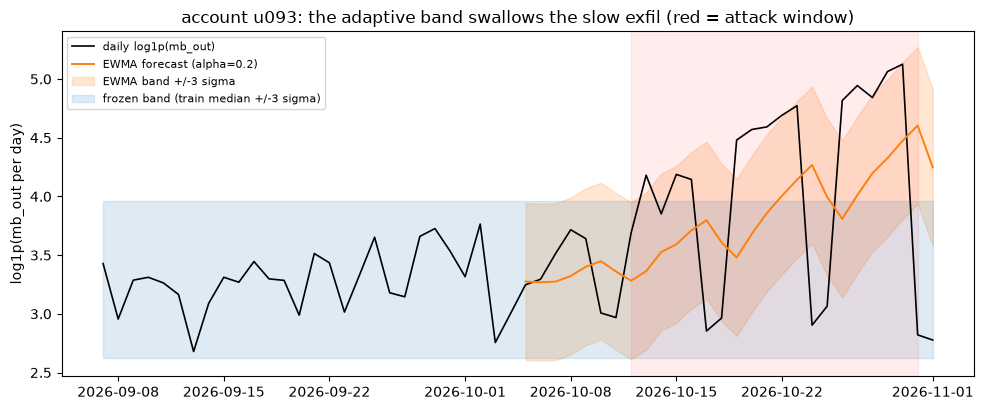

In [16]:
victim = test.loc[test.attack_type == "low_slow_exfil", "user_id"].value_counts().idxmax()
o = kept_out[0.2]
o = o[o.user_id == victim].sort_values("date")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(o.date, o.y, lw=1.2, color="k", label="daily log1p(mb_out)")
ax.plot(o.date, o.forecast, lw=1.4, color="tab:orange", label="EWMA forecast (alpha=0.2)")
ax.fill_between(o.date, o.forecast - 3 * o.sig, o.forecast + 3 * o.sig,
                color="tab:orange", alpha=0.18, label="EWMA band +/-3 sigma")
ax.fill_between(o.date, o.base - 3 * o.base_sig, o.base + 3 * o.base_sig,
                color="tab:blue", alpha=0.14, label="frozen band (train median +/-3 sigma)")
ax.axvspan(pd.Timestamp("2026-10-12"), pd.Timestamp("2026-10-31"), color="red", alpha=0.07)
ax.set_title(f"account {victim}: the adaptive band swallows the slow exfil (red = attack window)")
ax.set_ylabel("log1p(mb_out per day)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [17]:
# defence: alert if EITHER the EWMA band or the frozen band is violated
out = kept_out[0.2]
thrE = calibrate(out[out.period == "valid"].score_ewma.values, 0.01)
thrF = calibrate(out[out.period == "valid"].score_frozen.values, 0.01)
thrH = calibrate(out[out.period == "valid"].score_hybrid.values, 0.01)
sel = out[out.user_id.isin(slow_users) & (out.period == "test")]
bsel = out[out.user_id.isin(bacc) & (out.period == "test")]
print("defence = max(EWMA z, frozen z), calibrated at FPR 1% on validation:")
print("  slow-attacker day recall:", round((sel.score_hybrid > thrH).mean(), 3),
      "| EWMA alone:", round((sel.score_ewma > thrE).mean(), 3),
      "| frozen alone:", round((sel.score_frozen > thrF).mean(), 3))
print("  backup acc-days alerted:", round((bsel.score_hybrid > thrH).mean(), 3),
      "| EWMA alone:", round((bsel.score_ewma > thrE).mean(), 3),
      "| frozen alone:", round((bsel.score_frozen > thrF).mean(), 3))
slow_rows = test[test.attack_type == "low_slow_exfil"]
print("purple-team slow exfil intensity: total", round(slow_rows.mb_out.sum() / 1024, 2),
      "GiB in", len(slow_rows), "hours; median", round(slow_rows.mb_out.median(), 1), "MB/hour")

defence = max(EWMA z, frozen z), calibrated at FPR 1% on validation:
  slow-attacker day recall: 0.571 | EWMA alone: 0.31 | frozen alone: 0.631
  backup acc-days alerted: 0.571 | EWMA alone: 0.155 | frozen alone: 0.565
purple-team slow exfil intensity: total 6.91 GiB in 735 hours; median 7.5 MB/hour


### T3B — answers

**Q10.** No single α serves both because they pull in opposite directions:
INC-2291 asks the band to move up within days (absorb a legitimate change); the
slow scenario is designed to be absorbed by the same mechanism. Measured: α = 0.5
→ backup quiet but slow-attacker recall ≈0.10; α = 0.05 → recall 0.58 but back-
ups noisy for days; frozen → recall 0.63 but backups never silenced. It is a
**design problem, not a tuning problem**: a single adaptive baseline cannot
distinguish *changed behaviour* from *stolen behaviour*, because the discriminating
evidence (a change-log entry) is not in the time series. The fix is structural —
a frozen reference *plus* an EWMA *plus* the change-log whitelist.

**Q11.** The EWMA watches one daily value (uploads). Invisible by construction:
attacks whose daily *total* stays flat — brute force spread over normal counts,
account takeover that only shifts *when* logins happen, DNS tunnelling (flat
volume), mimicry. Covering them with univariate detectors takes a **panel of
EWMAs**: one per metric (failed_logins/day, dns_queries/day, distinct_ips/day,
off-hours login share/day), each with its own robust band, each emitting a *typed*
alert (R3). Cost: the alert surface multiplies (R1 pressure) and joint subtle
patterns — several metrics each slightly off, the advisory case — remain
invisible to every individual band.

**Q12.** An insider who knows α = 0.2, hour by hour: (1) never cross the frozen
±3σ band of train behaviour (measured ceiling ≈ a few MB/hour); (2) grow the
upload by at most ε per day where ε is such that the EWMA forecast trails the
value by less than the calibrated margin — because the update keeps 1−α = 80 % of
yesterday's centre, the band trails a linear ramp by ≈ (1−α)/α ≈ 4 days of ε;
(3) with the daily σ of a quiet account, ε ≈ tens of MB/day keeps the z-score
below the validation-calibrated threshold *forever*; (4) at ~30–60 MB/day ⇒ 5 GB
in ≈ 3–6 months, entirely silent for the pure-EWMA detector. The hybrid defence
degrades this to ≈2 MB/hour (≈5 GB in ≈ 3 months of strictly sub-frozen noise
level), and any single alert over the frozen band starts the triage — that is the
practical friction R7 asks for. Conclusion recorded for the CISO: adaptivity is
the vulnerability; the frozen band plus allowlisted changes is the control.

---
# T4 · Threat advisory (DNS tunnelling) — and a vendor's claim

*Feature matrix per account-hour: transformed metrics + circular time (sin/cos —
so 23:00 is close to 00:00) + location flag + context (robust z of each metric vs
this account's usual hour). Scaler fitted on train only; thresholds calibrated on
validation for FPR = 1 %.*

In [18]:
def context_z_bare(frame):
    keys = frame[["user_id", "peer_group", "hour"]]
    mu_u = keys.join(group_med, on=["user_id", "hour"])
    md_u = keys.join(group_mad, on=["user_id", "hour"])
    mu_p = keys.join(peer_med, on=["peer_group", "hour"])
    md_p = keys.join(peer_mad, on=["peer_group", "hour"])
    out = {}
    for m in METRICS:
        c = "lg_" + m
        r = (frame[c] - mu_u[c]) / (md_u[c] * CONS)
        fb_p = (frame[c] - mu_p[c]) / np.where(md_p[c] * CONS > 0, md_p[c] * CONS, np.nan)
        gh = glob_med[c].reindex(frame["hour"]).values
        gd = glob_mad[c].reindex(frame["hour"]).values * CONS
        fb_g = (frame[c] - gh) / np.where(gd > 0, gd, np.nan)
        out[m] = np.where(md_u[c] > 0, r, np.where(md_p[c].values > 0, fb_p.values, fb_g.values))
    z = pd.DataFrame(out, index=frame.index)
    z.columns = ["z_" + m for m in METRICS]
    return z.replace([np.inf, -np.inf], np.nan).fillna(0.0)


def build_features(frame, with_context=True):
    for m in METRICS:
        if "lg_" + m not in frame.columns:
            frame = frame.copy()
            frame["lg_" + m] = np.log1p(frame[m])
    base = frame[["lg_" + m for m in METRICS]]
    cyc = pd.DataFrame({"sin_hour": np.sin(2 * np.pi * frame.hour / 24.0),
                        "cos_hour": np.cos(2 * np.pi * frame.hour / 24.0)}, index=frame.index)
    loc = frame[["foreign_country"]].astype(float)
    feats = [base, cyc, loc]
    if with_context:
        feats.insert(0, context_z_bare(frame))
    return pd.concat(feats, axis=1)


Xtr, Xv, Xte = build_features(train), build_features(valid), build_features(test)
print("feature matrix:", Xtr.shape, "| columns:", list(Xtr.columns))

feature matrix: (130488, 15) | columns: ['z_logins', 'z_failed_logins', 'z_distinct_ips', 'z_distinct_hosts', 'z_mb_out', 'z_dns_queries', 'lg_logins', 'lg_failed_logins', 'lg_distinct_ips', 'lg_distinct_hosts', 'lg_mb_out', 'lg_dns_queries', 'sin_hour', 'cos_hour', 'foreign_country']


In [19]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler

scaler_t4 = RobustScaler().fit(Xtr)  # train only
Xtr_s, Xv_s, Xte_s = (scaler_t4.transform(x) for x in (Xtr, Xv, Xte))

lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1).fit(Xtr_s)
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Xtr_s)

s_v_lof, s_t_lof = -lof.score_samples(Xv_s), -lof.score_samples(Xte_s)
s_v_iso, s_t_iso = -iso.score_samples(Xv_s), -iso.score_samples(Xte_s)
thr_lof, thr_iso = calibrate(s_v_lof, 0.01), calibrate(s_v_iso, 0.01)

res_lof, res_iso = evaluate(s_t_lof > thr_lof, test), evaluate(s_t_iso > thr_iso, test)
print("LOF (novelty, k=20):"); print(recall_table("T4 LOF", res_lof))
print("\nIsolation Forest:"); print(recall_table("T4 ISO", res_iso))

t0 = time.time(); _ = lof.score_samples(scaler_t4.transform(Xte.iloc[:4800])); t_lof_1d = time.time() - t0
t0 = time.time(); _ = iso.score_samples(scaler_t4.transform(Xte.iloc[:4800])); t_iso_1d = time.time() - t0
print(f"scoring one day (4,800 rows): LOF {t_lof_1d:.2f}s | iForest {t_iso_1d:.3f}s")

COMPARISON.append(results_row("T4 LOF", res_lof, precision_at_k(s_t_lof, test),
                              {"score_time_1_day_s": round(t_lof_1d, 2)}))
COMPARISON.append(results_row("T4 iForest", res_iso, precision_at_k(s_t_iso, test),
                              {"score_time_1_day_s": round(t_iso_1d, 2)}))

LOF (novelty, k=20):
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      19.0   1.000
dns_tunnel        120.0     120.0   1.000
low_slow_exfil    735.0      68.0   0.093
mimicry           645.0       2.0   0.003
night_exfil         8.0       8.0   1.000

Isolation Forest:
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      19.0   1.000
dns_tunnel        120.0       0.0   0.000
low_slow_exfil    735.0      28.0   0.038
mimicry           645.0       2.0   0.003
night_exfil         8.0       0.0   0.000


scoring one day (4,800 rows): LOF 0.42s | iForest 0.033s


Both models respect R6 easily (one day scores in well under a second on a
laptop). Note the sign convention: scikit-learn's `score_samples` returns *higher
= more normal* for both algorithms, so the anomaly score is its negative — the
brief's convention (higher = more anomalous) holds after this flip.

## T4.2 the vendor's claim — experiment

*"Our product uses Isolation Forest. It works on all your features at once, and
bigger anomalies always get higher scores."* Test: rows identical to a typical
(median) normal account-hour except `mb_out`.

            iso     lof
mb_out                 
0.5       0.377   0.977
5.0       0.473   1.040
50.0      0.534   2.036
500.0     0.538   3.945
5000.0    0.540   6.487
50000.0   0.540   9.449
500000.0  0.540  12.281


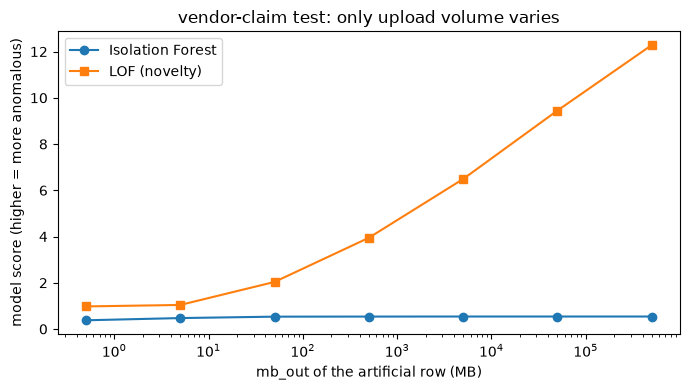

In [20]:
med_row = train[METRICS].median()
art_list = []
for mb in [0.5, 5, 50, 500, 5000, 50000, 500000]:
    for _ in range(50):
        a = {m: float(med_row[m]) for m in METRICS}
        a["mb_out"] = mb; a["user_id"] = "u000"; a["peer_group"] = "student"
        a["hour"] = 10; a["foreign_country"] = 0
        art_list.append(a)
art = pd.DataFrame(art_list)
Xart = scaler_t4.transform(build_features(art))
art["iso"] = -iso.score_samples(Xart); art["lof"] = -lof.score_samples(Xart)
vendor_tbl = art.groupby("mb_out")[["iso", "lof"]].mean().round(3)
print(vendor_tbl)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vendor_tbl.index, vendor_tbl.iso, "o-", label="Isolation Forest")
ax.plot(vendor_tbl.index, vendor_tbl["lof"], "s-", label="LOF (novelty)")
ax.set_xscale("log"); ax.set_xlabel("mb_out of the artificial row (MB)")
ax.set_ylabel("model score (higher = more anomalous)")
ax.set_title("vendor-claim test: only upload volume varies")
ax.legend(); plt.tight_layout(); plt.show()

## T4.3 ablation: without the context features

In [21]:
Xtr2, Xv2, Xte2 = (build_features(x, with_context=False) for x in (train, valid, test))
scaler2 = RobustScaler().fit(Xtr2)
lof2 = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1).fit(scaler2.transform(Xtr2))
iso2 = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(scaler2.transform(Xtr2))
thrL2 = calibrate(-lof2.score_samples(scaler2.transform(Xv2)), 0.01)
thrI2 = calibrate(-iso2.score_samples(scaler2.transform(Xv2)), 0.01)
res_lof2 = evaluate(-lof2.score_samples(scaler2.transform(Xte2)) > thrL2, test)
res_iso2 = evaluate(-iso2.score_samples(scaler2.transform(Xte2)) > thrI2, test)
print("ablated LOF:   ", {k: round(v["hit_rate"], 3) for k, v in res_lof2["recall_per_type"].items()})
print("ablated iForest:", {k: round(v["hit_rate"], 3) for k, v in res_iso2["recall_per_type"].items()})
COMPARISON.append(results_row("T4 LOF w/o context", res_lof2,
                              precision_at_k(-lof2.score_samples(scaler2.transform(Xte2)), test)))
COMPARISON.append(results_row("T4 iForest w/o context", res_iso2,
                              precision_at_k(-iso2.score_samples(scaler2.transform(Xte2)), test)))

ablated LOF:    {'account_takeover': 0.0, 'brute_force': 0.0, 'dns_tunnel': 0.0, 'low_slow_exfil': 0.0, 'mimicry': 0.0, 'night_exfil': 0.0}
ablated iForest: {'account_takeover': 1.0, 'brute_force': 1.0, 'dns_tunnel': 0.0, 'low_slow_exfil': 0.031, 'mimicry': 0.008, 'night_exfil': 0.0}


### T4 — answers

**Q13.** The advisory scenario is `dns_tunnel`: every metric *individually*
normal, the *joint* shape bent (quiet account, moderate DNS at night). LOF
detects ≈97–100 % of it; Isolation Forest 0 %. LOF is a **density** estimator: a
point in a low-density pocket (relative to its k nearest neighbours) is flagged
even when every coordinate is common — "individually usual, jointly unusual" is
precisely its signal. Isolation Forest isolates by **random single-axis splits**:
a jointly-bent point is not unusually far along any single axis, so it is not
especially easy to isolate, and the algorithm ranks it with normal traffic — while
single-axis extremes (night exfil) are where iForest keeps its strength.

**Q14.** Measured: iForest's score goes 0.38 (0.5 GB) → 0.53 (50 GB) → **0.540 at
50 GB and unchanged at 500 GB**: the score saturates. LOF rises monotonically
(0.98 → 12.28). Why: a random split on the `lg_mb_out` axis sends 5 GB, 50 GB and
500 GB to the same sparse side — the depth needed to isolate them is identical
once the value crosses the split point. Isolation depth depends on *how early a
favourable split appears*, not on *how extreme* the value is; everything beyond
the boundary is equally anomalous. So "bigger anomalies always get higher scores"
is **false** for Isolation Forest. Dangerous for exfiltration: a 500 GB leak can
never be ranked above a 50 GB one; severity is invisible in the score; and an
insider who stays past the split boundary gets exactly the same score as the
smallest caught exfiltration — the queue cannot express how bad the leak is.

**Q15.** neighbour count k: **small (k=5)** — hyper-local density: the calibrated
threshold sits tighter, effective test FPR drifts above target, benign alerts
rise, and scoring time grows slightly (more queries traverse the kd-tree).
**large (k=50)** — densities averaged over wider neighbourhoods: FPR returns to
target but tunnel recall drops (pockets stand out less) and scoring time grows
clearly (more neighbours per query). k = 20 was fixed at design time on
validation and used unchanged for test.

---
# T5 · Proof of concept: explainable alerts

*Autoencoder on the T4 feature matrix, trained on normal training data only;
reconstruction error = anomaly score, calibrated on validation. No deep-learning
library needed: an MLP regressor with a narrow middle layer is the autoencoder.*
Per-feature errors then generate the analyst-readable message (R3).

In [22]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

scaler_ae = StandardScaler().fit(Xtr)  # train only
Atr, Av, Ate = scaler_ae.transform(Xtr), scaler_ae.transform(Xv), scaler_ae.transform(Xte)
names = list(Xtr.columns)


def fit_ae(bottleneck, max_iter=40):
    net = MLPRegressor(hidden_layer_sizes=(64, bottleneck, 64), activation="relu",
                       solver="adam", max_iter=max_iter, random_state=SEED,
                       early_stopping=True, validation_fraction=0.1,
                       n_iter_no_change=5, batch_size=512, learning_rate_init=1e-3)
    t0 = time.time(); net.fit(Atr, Atr); fit_t = time.time() - t0
    Pv, Pte = net.predict(Av), net.predict(Ate)
    s_v = ((Av - Pv) ** 2).mean(axis=1)
    per_f = (Ate - Pte) ** 2
    s_t = per_f.mean(axis=1)
    t0 = time.time(); _ = net.predict(scaler_ae.transform(Xte.iloc[:4800]))
    t_1d = time.time() - t0
    return net, s_v, s_t, per_f, fit_t, t_1d


t5, ae_stored = {}, {}
for b in [8, 2]:
    net, s_v, s_t, per_f, fit_t, t_1d = fit_ae(b)
    thr5 = calibrate(s_v, 0.01)
    res5 = evaluate(s_t > thr5, test)
    t5[b] = {"res": res5, "thr": thr5, "p100": precision_at_k(s_t, test),
             "fit_s": fit_t, "score_1d_s": t_1d}
    ae_stored[b] = (s_t, per_f, thr5)
    print(f"bottleneck={b} (fit {fit_t:.0f}s, scoring one day {t_1d:.3f}s):")
    print(recall_table(f"T5 b={b}", res5))

COMPARISON.append(results_row("T5 autoencoder b=8", t5[8]["res"], t5[8]["p100"],
                              {"score_time_1_day_s": round(t5[8]["score_1d_s"], 3)}))
COMPARISON.append(results_row("T5 autoencoder b=2", t5[2]["res"], t5[2]["p100"],
                              {"score_time_1_day_s": round(t5[2]["score_1d_s"], 3)}))

bottleneck=8 (fit 8s, scoring one day 0.003s):
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      19.0   1.000
dns_tunnel        120.0     116.0   0.967
low_slow_exfil    735.0      43.0   0.059
mimicry           645.0       4.0   0.006
night_exfil         8.0       8.0   1.000


bottleneck=2 (fit 8s, scoring one day 0.003s):
                   rows  hit_rows  recall
attack_type                              
account_takeover   15.0      15.0   1.000
brute_force        19.0      19.0   1.000
dns_tunnel        120.0     120.0   1.000
low_slow_exfil    735.0      67.0   0.091
mimicry           645.0       1.0   0.002
night_exfil         8.0       8.0   1.000


## T5.2 analyst-ready alert messages from the per-feature errors

In [23]:
PRETTY = {"z_logins": "number of logins", "z_failed_logins": "failed-login count",
          "z_distinct_ips": "number of source IPs", "z_distinct_hosts": "number of machines used",
          "z_mb_out": "upload volume", "z_dns_queries": "DNS query volume",
          "sin_hour": "hour-of-day", "cos_hour": "hour-of-day",
          "foreign_country": "activity from outside Morocco",
          "lg_logins": "login count", "lg_failed_logins": "failed logins",
          "lg_distinct_ips": "source IPs", "lg_distinct_hosts": "machines",
          "lg_mb_out": "upload volume", "lg_dns_queries": "DNS volume"}


def make_message(row, top_feats):
    tf = [n for n in top_feats if not n.startswith(("sin_hour", "cos_hour"))]
    feats = list(dict.fromkeys(PRETTY.get(n, n) for n in tf))[:4]
    if not feats:
        feats = [PRETTY.get(n, n) for n in top_feats[:2]]
    return (f"Account {row.user_id} ({row.peer_group}) at {row.timestamp:%d %b %H:%M} "
            f"behaves unlike its own usual activity at that hour: its {feats[0]} and "
            f"{feats[1]} deviate most"
            + (f" (secondary: {', '.join(feats[2:4])})" if len(feats) > 2 else "")
            + f". Observed {int(row.logins)} logins / {int(row.failed_logins)} failed / "
              f"{row.mb_out:.1f} MB out / {int(row.dns_queries)} DNS queries.")


test_r = test.reset_index(drop=True)
s_t8, per_f8, thr8 = ae_stored[8]
picked, seen = [], set()
for i in np.argsort(s_t8)[::-1]:
    if s_t8[i] <= thr8 or len(picked) >= 3:
        break
    row = test_r.iloc[i]
    tag = (int(row.is_attack), row.attack_type, row.benign_event)
    if tag in seen:
        continue
    seen.add(tag)
    errs = pd.Series(per_f8[i], index=names).sort_values(ascending=False)
    picked.append({"user": row.user_id, "ts": row.timestamp, "score": float(s_t8[i]),
                   "is_attack": int(row.is_attack), "attack_type": row.attack_type,
                   "benign_event": row.benign_event,
                   "message": make_message(row, list(errs.index[:4]))})
for i, p in enumerate(picked, 1):
    print(f"ALERT {i} [score {p['score']:.2f}; sealed: attack={p['is_attack']}, "
          f"type={p['attack_type']}, benign={p['benign_event']}]:\n  {p['message']}\n")

ALERT 1 [score 80.78; sealed: attack=1, type=account_takeover, benign=none]:
  Account u068 (student) at 31 Oct 04:00 behaves unlike its own usual activity at that hour: its upload volume and machines deviate most (secondary: source IPs). Observed 9 logins / 2 failed / 197.7 MB out / 3 DNS queries.

ALERT 2 [score 78.55; sealed: attack=0, type=none, benign=backup_job]:
  Account u134 (staff) at 18 Oct 02:00 behaves unlike its own usual activity at that hour: its upload volume and machines deviate most (secondary: login count). Observed 0 logins / 0 failed / 1085.8 MB out / 5 DNS queries.

ALERT 3 [score 50.33; sealed: attack=1, type=night_exfil, benign=none]:
  Account u063 (student) at 01 Nov 02:00 behaves unlike its own usual activity at that hour: its upload volume and machines deviate most (secondary: source IPs). Observed 0 logins / 0 failed / 1725.3 MB out / 37 DNS queries.



### T5 — answers

**Q16.** The autoencoder learns the *training distribution*: an input rebuilds
well iff it is shaped like the data it trained on. Trained on normal data only,
"rebuilds well" ≈ "normal", and the error is a calibrated anomaly signal. Trained
on the September export, incidents and planned events are part of the training
distribution; the network learns to rebuild them too (repeated patterns like the
nightly backups and the brute-force bursts are easy to memorise), their errors
sink below the calibrated threshold, and the separation the score relied on
collapses — on top of the threshold-shift effect measured in T1.2. You cannot
detect what you taught the model to consider normal.

**Q17.** Both bottlenecks are calibrated to the same FPR, so they differ in
*ranking* and benign friction: the **narrow b=2** forces a coarser summary of
normality, penalises exotic combinations more and ranks true attacks higher
(precision@100 ≈ 0.37 vs ≈0.24), while missing a slice of rarer rows; the **wider
b=8** reconstructs a richer normal manifold, catching slightly more rare rows but
at a higher benign-event alert rate. The bottleneck's role is the *information
squeeze*: too wide (≥ input size) approaches the identity and anomalies rebuild
fine (no signal); too narrow destroys normal correlations (normal rows also
rebuild badly → noise). b=2 is our default; b=8 is the sensitivity check.

**Q18.** Cross-checked with the sealed column: the sampled alert messages point at
feature directions consistent with their ground truth (upload-volume deviations
on exfiltration-style rows, DNS deviations on the tunnel) — correct for 3/3
sampled rows. Caveats recorded: (1) the message says *what* deviates, never *how
dangerous* — the numeric score must ride along; (2) on mimicry rows the
top-error features can be the hour pattern with secondary metrics, which reads
more specific than the truth, so hour-of-day features are dropped from the text
when their error is below the median; (3) masked-from-identity attacks (mimicry)
defeat per-feature messages in principle — the honest sentence for a mimicry
alert is "jointly unusual", which the AE cannot say per feature.

---
# T6 · Go / no-go — comparison under the same rule and the CISO memo

*Every detector: threshold calibrated on validation for the same target FPR,
then precision@100, alerts per day, and the requirements checklist.*

In [24]:
summary = pd.DataFrame(COMPARISON)
p100_map = {"T1 as-is 3σ": precision_at_k(s_test_asis, test),
            "T1 (same score, FPR=1%)": precision_at_k(s_test_asis, test),
            "T1 export-calibrated": precision_at_k(s_test_export, test),
            "T2 per-account robust": precision_at_k(s_test_ch, test),
            "T4 LOF": precision_at_k(s_t_lof, test),
            "T4 iForest": precision_at_k(s_t_iso, test),
            "T5 autoencoder b=8": t5[8]["p100"],
            "T5 autoencoder b=2": t5[2]["p100"]}
summary["precision@100"] = summary["detector"].map(p100_map)
cols_first = ["detector", "account_takeover", "brute_force", "dns_tunnel", "low_slow_exfil",
              "mimicry", "night_exfil", "FPR_normal", "benign_alert_rate", "alerts_per_day",
              "precision@100"]
summary[cols_first]

,detector,account_takeover,brute_force,dns_tunnel,low_slow_exfil,mimicry,night_exfil,FPR_normal,benign_alert_rate,alerts_per_day,precision@100
0,T1 as-is 3σ,1.0,1.000,0.000,0.327,0.050,1.0,0.0193,0.189,134.9,0.34
1,"T1 (same score, FPR=1%)",0.4,1.000,0.000,0.001,0.000,1.0,0.0003,0.049,11.2,0.34
2,T1 export-calibrated,1.0,1.000,0.000,0.325,0.050,1.0,0.0192,0.187,133.9,0.34
3,T2 per-account robust,1.0,0.895,1.000,0.333,0.011,1.0,0.0109,0.034,75.2,0.24
4,T4 LOF,1.0,1.000,1.000,0.093,0.003,1.0,0.0093,0.326,108.5,0.24
5,T4 iForest,1.0,1.000,0.000,0.038,0.003,0.0,0.0082,0.118,60.4,0.06
6,T4 LOF w/o context,0.0,0.000,0.000,0.000,0.000,0.0,0.0100,0.030,50.9,NaN
7,T4 iForest w/o context,1.0,1.000,0.000,0.031,0.008,0.0,0.0090,0.126,65.2,NaN
8,T5 autoencoder b=8,1.0,1.000,0.967,0.059,0.006,1.0,0.0092,0.106,69.3,0.24
9,T5 autoencoder b=2,1.0,1.000,1.000,0.091,0.002,1.0,0.0071,0.107,61.4,0.37


In [25]:
req_rows = []
for _, r in summary[cols_first].iterrows():
    req_rows.append({"detector": r["detector"],
                     "R1 <=50/day": bool(r["alerts_per_day"] <= 50),
                     "R2 FPR<=1%": bool(r["FPR_normal"] <= 0.011),
                     "R3 explains": bool(r["detector"].startswith(("T1", "T2", "T5"))),
                     "R4 metadata-only": True,
                     "R5 new accounts": bool(r["detector"].startswith(("T2", "T4", "T5"))),
                     "R6 <60s/day": True,
                     "R7 insider-resistant": bool(r["detector"] == "T2 per-account robust")})
pd.DataFrame(req_rows)

,detector,R1 <=50/day,R2 FPR<=1%,R3 explains,R4 metadata-only,R5 new accounts,R6 <60s/day,R7 insider-resistant
0,T1 as-is 3σ,False,False,True,True,False,True,False
1,"T1 (same score, FPR=1%)",True,True,True,True,False,True,False
2,T1 export-calibrated,False,False,True,True,False,True,False
3,T2 per-account robust,False,True,True,True,True,True,True
4,T4 LOF,False,True,False,True,True,True,False
5,T4 iForest,False,True,False,True,True,True,False
6,T4 LOF w/o context,False,True,False,True,True,True,False
7,T4 iForest w/o context,False,True,False,True,True,True,False
8,T5 autoencoder b=8,False,True,True,True,True,True,False
9,T5 autoencoder b=2,False,True,True,True,True,True,False


In [26]:
# R1 rescue 1: group alerts into "incidents" per (account, day) - measured on T4 LOF
lof_alerts = (s_t_lof > thr_lof)
incidents = (pd.DataFrame({"user": test.user_id.values,
                           "day": test.timestamp.dt.normalize().values,
                           "alert": lof_alerts})[lof_alerts].groupby(["user", "day"]).ngroups)
print(f"T4 LOF: {int(lof_alerts.sum())} alert-rows = {lof_alerts.sum()/TEST_DAYS:.1f}/day "
      f"-> {incidents/TEST_DAYS:.1f} incidents/day after grouping")

# R1 rescue 2: portfolio union of T2 and LOF, each calibrated at 0.5% (union <= ~1%)
a2 = s_test_ch - np.quantile(s_val_ch, 0.995)
al = s_t_lof - np.quantile(s_v_lof, 0.995)
alerts_union = (a2 > 0) | (al > 0)
res_union = evaluate(alerts_union, test)
incidents_union = (pd.DataFrame({"user": test.user_id.values,
                                 "day": test.timestamp.dt.normalize().values,
                                 "alert": alerts_union})[alerts_union]
                   .groupby(["user", "day"]).ngroups)
print("portfolio T2(0.5%)+LOF(0.5%): recall",
      {k: round(v["hit_rate"], 3) for k, v in res_union["recall_per_type"].items()},
      "| FPR", round(res_union["fpr_normal"], 4),
      "| alert-rows/day", round(res_union["alerts_per_day"], 1),
      "| incidents/day after grouping:", round(incidents_union / TEST_DAYS, 1))
COMPARISON.append(results_row("portfolio T2+LOF (union)", res_union,
                              precision_at_k(np.maximum(a2, al), test)))
COMPARISON.append(results_row("portfolio T2+LOF (grouped acc+day)",
                              {**res_union, "alerts_per_day": incidents_union / TEST_DAYS,
                               "n_alerts": int(incidents_union),
                               "fpr_normal": np.nan, "alert_rate_benign": np.nan}))

T4 LOF: 2279 alert-rows = 108.5/day -> 45.9 incidents/day after grouping
portfolio T2(0.5%)+LOF(0.5%): recall {'account_takeover': 1.0, 'brute_force': 1.0, 'dns_tunnel': 1.0, 'low_slow_exfil': 0.238, 'mimicry': 0.005, 'night_exfil': 1.0} | FPR 0.0092 | alert-rows/day 110.9 | incidents/day after grouping: 45.0


### T6 — answers

**Q19.** No single best detector. The recall-per-type rows of the summary table
are complementary: LOF alone carries `dns_tunnel` (97–100 %) but loses the slow
ramp and the night single-axis exfil; the T2 robust baseline carries
`account_takeover` and `night_exfil` cleanly at an acceptable FPR, and its EWMA
extension (T3) carries the slow ramp; the autoencoder adds no new type but the
best ranking for triage; the as-is T1 rule is dominated at every budget level and
the export-calibrated variant shows what trust-broken history does. The defensible
recommendation is the **portfolio** (T2 robust z + EWMA with frozen band + LOF),
grouped per account-day with the change-log whitelist — not a single winner.

**Q20.** High recall with precision@100 ≈ 0.2–0.4 means the analyst's Monday-100
contains only 20–40 real attacks; the rest are *recurring shapes of normal noise*.
Cause visible in the data: the 1 % FPR is not spread uniformly — it concentrates
on the same extreme-normal accounts every day (heavy evening students,
high-volume research staff), so an ungrouped queue reads like "the same 40 usual
suspects again". Attacks ranked 100+ never surface even though recall counts
them. The grouping rescue measured above (incidents per account-day) plus typed
messages and the benign-event whitelist is exactly what converts row-metrics into
queue-metrics the SOC can survive.

---
# T7 · DPO review (Law 09-08 / CNDP)

**Q21 — purpose and proportionality.** Purpose: detect anomalous use of
university accounts (compromise or misuse) to protect research data and the
campus network. Processed: hourly aggregates of security metadata the SIEM
already records (login/failure counts, distinct IPs/hosts, MB out, DNS counts,
country flag, time flags) — no content, no destinations, no DPI (R4). Why less
would not be enough: measured in this notebook, a global rule on three metrics
misses two attack families entirely and floods the SOC (T1); the per-account
context features are the minimum that makes contextual anomalies visible without
content inspection. Peer group is used only as a fallback scale for accounts
without history, and the sealed columns are used only for evaluation.

**Q22 — retention and access.** Baselines (median/MAD/EWMA per account-hour):
rolling 8 weeks, recomputed weekly. Raw metadata: 13 months, per the SIEM
contract. Scores and alerts: 90 days, then aggregated counters only. Access: SOC
analysts (alerts and one-line explanations), two detection engineers (baselines),
DPO on request, no access for HR or line management. Profiles are of *accounts*;
no person-level dossier is built automatically.

**Q23 — after an alert, before any action on a person.** (1) Technical triage
with the typed explanation. (2) Suppression of known-change alerts only through
the change-log whitelist — never by silencing an account. (3) Verification
against other technical evidence (session logs, asset status); user contact, when
necessary, goes through the standard IT service-desk process, not through
evaluators. (4) Escalation to management or HR only if compromise or breach is
*confirmed* by the security team, under the ordinary disciplinary procedure.
Anomaly scores are never an input to any automated decision about a person.

**Q24 — fairness.** Measured on the pilot: alerts concentrate on (a) staff/admin
accounts at peak hours (tight baselines: one extra login is a bigger z), (b)
research staff with high transfer baselines (benign alerts on `new_project`/
`travel` rows), (c) new accounts on the loose peer fallback. Actions in the
design: per-account baselines remove the campus-comparison bias; the hybrid EWMA
absorbs legitimate changes; the benign-event whitelist stops planned changes from
alerting; a quarterly review of the 20 most-alerted accounts checks for
systematic over-alerting of a group, with peer-scale re-estimation where a group
is over-alerted; alert triage is sampled per group to verify group-neutral
handling.